# 🛡️ Project Panopticon: Intelligent Proctoring AI
**EduGuard AI - Machine Learning Division**

**Intern Name:** `Mohana priya R`  
**Date:** `2026-08-09`

---

### 📖 Executive Summary
Welcome to EduGuard AI. Our current proctoring system is blindly flagging innocent students for background noise and standard physical movements. Your objective is to build a robust, time-series Machine Learning pipeline that identifies true academic dishonesty while strictly protecting innocent students through asynchronous data merging and mathematical threshold tuning.

### 🗺️ Project Roadmap
1. **Data Ingestion:** Upload and parse asynchronous telemetry logs.
2. **Temporal Alignment:** Merge video and system logs using `merge_asof`.
3. **Signal Processing:** Impute missing data and engineer rolling windows.
4. **Classification:** Train an imbalanced-weighted predictive model.
5. **Ethical AI Tuning:** Shift decision boundaries to guarantee 90%+ precision.

In [ ]:
# ==========================================
# 0. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Imports
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# Set visualization styles
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


---
## Phase 1: Data Ingestion & Temporal Alignment
> ⚠️ **The Asynchronous Trap:** Video telemetry records exactly every 1 second. System events (like tab switches) only record when the student actually clicks something. You cannot use a standard `pd.merge()`.

**Instructions:**
1. Upload the `video_telemetry.csv` and `system_events.csv` files.
2. Convert the timestamp columns to datetime objects.
3. Sort the dataframes and merge them using Pandas `merge_asof`.

In [ ]:
# ==========================================
# 1A/1B. LOAD DATA (embedded - no upload needed)
# ==========================================
import base64, io

video_csv_b64 = "..."
sys_csv_b64 = "dGltZXN0YW1wLHRhYl9zd2l0Y2hlcyxpc19jaGVhdGluZwoyMDIzLTEyLTAxIDA4OjAwOjMyLjE4MTI5NiwxLDAKMjAyMy0xMi0wMSAwODowMTowMS45MjM3NzgsMSwxCjIwMjMtMTItMDEgMDg6MDE6MjQuNDYyODA4LDEsMAoyMDIzLTEyLTAxIDA4OjA0OjEwLjYxMDc0MywxLDAKMjAyMy0xMi0wMSAwODowNDoyMy45MDI4MTQsMSwwCjIwMjMtMTItMDEgMDg6MDU6MDYuOTkxMzUzLDEsMAoyMDIzLTEyLTAxIDA4OjA1OjQ1LjM0ODkxOCwxLDAKMjAyMy0xMi0wMSAwODoxMDoyNy43MDU3ODksMSwwCjIwMjMtMTItMDEgMDg6MTA6MjguNjM0MTQ2LDEsMQoyMDIzLTEyLTAxIDA4OjExOjQ1LjQ3MTYyMiwxLDAKMjAyMy0xMi0wMSAwODoxMjowOC40MDM2NzAsMSwwCjIwMjMtMTItMDEgMDg6MTI6NTYuOTg1ODA4LDIsMQoyMDIzLTEyLTAxIDA4OjEzOjQzLjc3ODA1OSwxLDAKMjAyMy0xMi0wMSAwODoxNTo1My42MzAyODUsMiwxCjIwMjMtMTItMDEgMDg6MTY6MDUuNTQxMzUzLDIsMQoyMDIzLTEyLTAxIDA4OjE2OjA2LjI2ODYwOSwxLDAKMjAyMy0xMi0wMSAwODoxNjozNC4zNzQyODQsMiwxCjIwMjMtMTItMDEgMDg6MTc6MjAuODQ4MjM5LDEsMAoyMDIzLTEyLTAxIDA4OjE4OjAzLjYwNDQ5MywxLDAKMjAyMy0xMi0wMSAwODoxODoxNi4yNDk3NDUsMSwwCjIwMjMtMTItMDEgMDg6MTg6MzAuNjU4NTQ5LDEsMAoyMDIzLTEyLTAxIDA4OjE4OjM3LjYzODIwMSwzLDEKMjAyMy0xMi0wMSAwODoxOTo1OS4wMjk1MzcsMSwwCjIwMjMtMTItMDEgMDg6MjA6MDEuMjQ1ODMzLDMsMQoyMDIzLTEyLTAxIDA4OjIwOjA1LjY1MTgyNiwyLDEKMjAyMy0xMi0wMSAwODoyMTowNy43OTg4ODgsMSwwCjIwMjMtMTItMDEgMDg6MjI6MzQuNDkyNTQ0LDEsMAoyMDIzLTEyLTAxIDA4OjIzOjI3Ljk2NjYyMywxLDAKMjAyMy0xMi0wMSAwODoyNToyNy4wMjk3MDksMSwwCjIwMjMtMTItMDEgMDg6MjY6MTUuMDAzODUwLDEsMQoyMDIzLTEyLTAxIDA4OjMwOjIwLjc2NDU0NywxLDAKMjAyMy0xMi0wMSAwODozMDozMi4yNDM1ODYsMSwwCjIwMjMtMTItMDEgMDg6MzE6NDQuODkzMjIzLDEsMAoyMDIzLTEyLTAxIDA4OjMyOjEwLjYwNzgzOCwyLDEKMjAyMy0xMi0wMSAwODozMjoxMS43MDc2NjAsMywxCjIwMjMtMTItMDEgMDg6MzI6MTYuNDMxMDMyLDMsMQoyMDIzLTEyLTAxIDA4OjMyOjI3LjA2NTk2NiwyLDEKMjAyMy0xMi0wMSAwODozNTozNS42OTkyMjksMSwxCjIwMjMtMTItMDEgMDg6MzU6MzYuMDkzMzk1LDIsMQoyMDIzLTEyLTAxIDA4OjM4OjQ0LjIwMDI1MiwxLDEKMjAyMy0xMi0wMSAwODozODo1MC4yODg2NjYsMywxCjIwMjMtMTItMDEgMDg6Mzg6NTQuNzc2MzEyLDMsMQoyMDIzLTEyLTAxIDA4OjQwOjU3Ljc2OTk2MCwyLDEKMjAyMy0xMi0wMSAwODo0MToyMi4yOTgzMjcsMSwwCjIwMjMtMTItMDEgMDg6NDU6MDcuNjM1NDY0LDEsMAoyMDIzLTEyLTAxIDA4OjQ1OjIzLjkyODE5OSwxLDAKMjAyMy0xMi0wMSAwODo0NjowMS45NjExOTcsMSwxCjIwMjMtMTItMDEgMDg6NDY6MDIuNDgxNzAzLDEsMQoyMDIzLTEyLTAxIDA4OjQ2OjA0LjY1NDIxOSwxLDAKMjAyMy0xMi0wMSAwODo0NjowOS40OTA2NjEsMiwxCjIwMjMtMTItMDEgMDg6NDY6MjQuMzU5MzI1LDMsMQoyMDIzLTEyLTAxIDA4OjQ2OjQ5LjUxMTA2OCwxLDAKMjAyMy0xMi0wMSAwODo1MDoyNy4zNTEwNTMsMSwwCjIwMjMtMTItMDEgMDg6NTE6NTMuNjAzMzg4LDEsMAoyMDIzLTEyLTAxIDA4OjUzOjM4LjYzMzE5NiwxLDEKMjAyMy0xMi0wMSAwODo1MzozOS44NjM3MTksMSwwCjIwMjMtMTItMDEgMDg6NTM6NDYuNDM5NjY0LDIsMQoyMDIzLTEyLTAxIDA4OjUzOjU2Ljc1MDk5NywzLDEKMjAyMy0xMi0wMSAwODo1NDoyNC4xNDY0ODcsMiwxCjIwMjMtMTItMDEgMDg6NTQ6MzAuNTA1ODgxLDIsMQoyMDIzLTEyLTAxIDA4OjU2OjM2LjU2NjkwNCwxLDEKMjAyMy0xMi0wMSAwODo1Njo1Ni43NTEzOTcsMSwxCjIwMjMtMTItMDEgMDg6NTc6MTMuMzEyNTA0LDEsMQoyMDIzLTEyLTAxIDA4OjU3OjE4LjYwODA0OCwzLDEKMjAyMy0xMi0wMSAwODo1NzozMS4zNjQzODksMSwwCjIwMjMtMTItMDEgMDg6NTg6MjUuNDI4NjY3LDMsMQoyMDIzLTEyLTAxIDA4OjU4OjM4Ljg0NjM0OSwxLDAKMjAyMy0xMi0wMSAwODo1ODo1Mi44OTY5NzQsMSwwCjIwMjMtMTItMDEgMDg6NTk6NDYuODYzOTEzLDEsMAoyMDIzLTEyLTAxIDA5OjAyOjE3LjU5MDc2MiwxLDAKMjAyMy0xMi0wMSAwOTowNDoxNi40ODE1NzMsMSwwCjIwMjMtMTItMDEgMDk6MTE6MTguNTYzMzcxLDEsMAoyMDIzLTEyLTAxIDA5OjEyOjI0LjkzMDc0OCwxLDAKMjAyMy0xMi0wMSAwOToxMjo0MC40NTU1ODgsMSwxCjIwMjMtMTItMDEgMDk6MTM6MTAuNDg1MDMxLDEsMAoyMDIzLTEyLTAxIDA5OjE2OjI0LjIzOTA0OCwxLDAKMjAyMy0xMi0wMSAwOToxNzowMy40ODYyMTQsMSwwCjIwMjMtMTItMDEgMDk6MTg6MDMuMDQ5NTYwLDIsMQoyMDIzLTEyLTAxIDA5OjE4OjE3LjYyNjMwNywzLDEKMjAyMy0xMi0wMSAwOToxODozNC40OTE5NTksMSwxCjIwMjMtMTItMDEgMDk6MTg6MzcuODc3MzE5LDMsMQoyMDIzLTEyLTAxIDA5OjE4OjQ4LjY2Njk1MiwyLDEKMjAyMy0xMi0wMSAwOToyMDowMy4zNjExMjcsMSwwCjIwMjMtMTItMDEgMDk6MjA6MTcuODM3OTQ3LDEsMAoyMDIzLTEyLTAxIDA5OjIzOjM0Ljc4NjUwOSwyLDEKMjAyMy0xMi0wMSAwOToyMzo1NC41NTc3NjgsMSwxCjIwMjMtMTItMDEgMDk6MjQ6MzIuMjU1NzI5LDEsMAoyMDIzLTEyLTAxIDA5OjI1OjI0LjQ0OTc1NywxLDAKMjAyMy0xMi0wMSAwOToyNTo0OS42OTQyNTYsMSwwCjIwMjMtMTItMDEgMDk6MjY6MTYuMzEzNDA0LDEsMAoyMDIzLTEyLTAxIDA5OjI4OjE4LjI3NzI0NSwxLDAKMjAyMy0xMi0wMSAwOToyOTowNy4wNzIxMTQsMSwwCjIwMjMtMTItMDEgMDk6Mjk6MTEuNjU1MzI5LDEsMAoyMDIzLTEyLTAxIDA5OjI5OjQzLjg5NDc0MywxLDAKMjAyMy0xMi0wMSAwOTozMzo1NC4yMTYwODIsMywxCjIwMjMtMTItMDEgMDk6MzQ6MDguMTA5MTA2LDEsMQoyMDIzLTEyLTAxIDA5OjM0OjEyLjY4MzMwOCwxLDEKMjAyMy0xMi0wMSAwOTozODo1Ni4zNjc0MDAsMSwwCjIwMjMtMTItMDEgMDk6NDA6MjMuOTMxMzQwLDEsMAoyMDIzLTEyLTAxIDA5OjQxOjE2LjA5NDQ3MiwxLDAKMjAyMy0xMi0wMSAwOTo0MToyOS42OTYzMTYsMSwxCjIwMjMtMTItMDEgMDk6NDE6NDQuMTU5NTQzLDEsMQoyMDIzLTEyLTAxIDA5OjQyOjI1LjkzNTA3MSwxLDAKMjAyMy0xMi0wMSAwOTo0NDowMi45MzQ3NzIsMSwwCjIwMjMtMTItMDEgMDk6NDQ6NTQuNTQwOTA2LDEsMAoyMDIzLTEyLTAxIDA5OjQ1OjU4LjQ1NTg5NywxLDAKMjAyMy0xMi0wMSAwOTo0NjozNy43NTc0MTIsMSwwCjIwMjMtMTItMDEgMDk6NDY6NDYuODQ4Njg4LDEsMAoyMDIzLTEyLTAxIDA5OjQ3OjQ2LjYxODI3MSwxLDAKMjAyMy0xMi0wMSAwOTo0ODo0NS4xNDc0NTcsMSwwCjIwMjMtMTItMDEgMDk6NDk6MTQuNTI4MzM0LDEsMAoyMDIzLTEyLTAxIDA5OjUyOjU3LjY5MjkzOSwyLDEKMjAyMy0xMi0wMSAwOTo1MzowNS45MDI3NTUsMSwwCjIwMjMtMTItMDEgMDk6NTM6MDcuNzkyNjE1LDMsMQoyMDIzLTEyLTAxIDA5OjUzOjIyLjE2MDgyNCwyLDEKMjAyMy0xMi0wMSAwOTo1MzoyNS42OTYyNjYsMSwxCjIwMjMtMTItMDEgMDk6NTM6MjguMzgzMjIyLDIsMQoyMDIzLTEyLTAxIDA5OjU0OjQ3Ljk2NzQ4NSwxLDAKMjAyMy0xMi0wMSAwOTo1NToxOC44NjA2NzcsMSwwCjIwMjMtMTItMDEgMDk6NTk6MDkuMzk1NTY0LDEsMAoyMDIzLTEyLTAxIDA5OjU5OjQxLjI5MDI3MCwzLDEKMjAyMy0xMi0wMSAwOTo1OTo0NC4wNTI4NzYsMSwxCjIwMjMtMTItMDEgMTA6MDA6MDkuNTQ3NzM4LDEsMAoyMDIzLTEyLTAxIDEwOjAxOjIyLjI2NDU4NywxLDAKMjAyMy0xMi0wMSAxMDowNDoxMi4zODE0MTksMiwxCjIwMjMtMTItMDEgMTA6MDQ6MTMuNzc0MTEzLDEsMAoyMDIzLTEyLTAxIDEwOjA2OjI2LjQyNTIxOCwxLDAKMjAyMy0xMi0wMSAxMDowODowMS45MzA2NzYsMiwxCjIwMjMtMTItMDEgMTA6MDg6MDYuMDc2NjQ2LDMsMQoyMDIzLTEyLTAxIDEwOjA4OjIxLjQwNTk5MCwxLDEKMjAyMy0xMi0wMSAxMDowODo0NS4zMzY5MjksMSwwCjIwMjMtMTItMDEgMTA6MTA6NDMuMTQ1ODkxLDEsMQoyMDIzLTEyLTAxIDEwOjE1OjU3LjA2MjMzNCwxLDAKMjAyMy0xMi0wMSAxMDoxNzoyOS43NzgzMzcsMSwwCjIwMjMtMTItMDEgMTA6MTg6MzkuOTAxNzY4LDEsMAoyMDIzLTEyLTAxIDEwOjE5OjE0LjQ3NDgwNiwxLDAKMjAyMy0xMi0wMSAxMDoxOToyMy43NTY2NjksMSwwCjIwMjMtMTItMDEgMTA6MjQ6MDQuNzc2NzE0LDEsMAoyMDIzLTEyLTAxIDEwOjI2OjA4LjQzMjU4OCwxLDAKMjAyMy0xMi0wMSAxMDoyNjoxMi40NjIzNTgsMSwwCjIwMjMtMTItMDEgMTA6Mjc6MDkuNzc0NjA5LDEsMAoyMDIzLTEyLTAxIDEwOjI3OjE5Ljg0Mjc1NCwxLDEKMjAyMy0xMi0wMSAxMDoyNzoyMC4yODIyNzUsMiwxCjIwMjMtMTItMDEgMTA6Mjc6MjguNzk1Mjg2LDIsMQoyMDIzLTEyLTAxIDEwOjI4OjE3LjQ3NzE3NSwxLDAKMjAyMy0xMi0wMSAxMDoyODo0My4xMjU2NzcsMSwwCjIwMjMtMTItMDEgMTA6Mjk6MzIuMDk0MjYyLDEsMQoyMDIzLTEyLTAxIDEwOjI5OjQyLjc0MTgyMywyLDEKMjAyMy0xMi0wMSAxMDoyOTo1MS41NTU3MjgsMywxCjIwMjMtMTItMDEgMTA6MzA6MDYuNjM5NTY2LDEsMAoyMDIzLTEyLTAxIDEwOjMwOjQ1LjQyODA2OCwxLDAKMjAyMy0xMi0wMSAxMDozMDo0Ny4zMDExMTQsMiwxCjIwMjMtMTItMDEgMTA6MzE6MDUuOTkyMjk0LDEsMAoyMDIzLTEyLTAxIDEwOjMyOjEzLjY5Mzk2MiwxLDAKMjAyMy0xMi0wMSAxMDozMjoyNy41NjM0MzAsMywxCjIwMjMtMTItMDEgMTA6MzI6MjkuMTQyOTc2LDEsMQoyMDIzLTEyLTAxIDEwOjM0OjE3LjgxMzk1NSwzLDEKMjAyMy0xMi0wMSAxMDozNDozMy4xODExNzQsMywxCjIwMjMtMTItMDEgMTA6MzQ6NDEuODA0NTk1LDMsMQoyMDIzLTEyLTAxIDEwOjM1OjI4LjU0NDUyNSwxLDAKMjAyMy0xMi0wMSAxMDozODo1MC41NjI0NDcsMSwxCjIwMjMtMTItMDEgMTA6Mzg6NTQuMDIwMDkyLDMsMQoyMDIzLTEyLTAxIDEwOjM4OjU1Ljk4MDYxOCwzLDEKMjAyMy0xMi0wMSAxMDozOTowMS45NDM5MzksMSwxCjIwMjMtMTItMDEgMTA6NDA6MzkuMTY0MDY5LDMsMQoyMDIzLTEyLTAxIDEwOjQ1OjAzLjY3MTc5NywzLDEKMjAyMy0xMi0wMSAxMDo0NTozOS45NjIwNjYsMSwwCg=="

video_df = pd.read_csv(io.BytesIO(base64.b64decode(video_csv_b64)))
sys_df = pd.read_csv(io.BytesIO(base64.b64decode(sys_csv_b64)))

video_df['timestamp'] = pd.to_datetime(video_df['timestamp'])
sys_df['timestamp'] = pd.to_datetime(sys_df['timestamp'])

video_df = video_df.sort_values('timestamp')
sys_df = sys_df.sort_values('timestamp')

# ==========================================
# 1C. ASYNCHRONOUS MERGE
# ==========================================
merged_df = pd.merge_asof(video_df, sys_df, on='timestamp', direction='backward')

merged_df.head()

,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating
0,2023-12-01 08:00:00,2.560857,36.553781,NaN,NaN
1,2023-12-01 08:00:01,10.177137,39.102627,NaN,NaN
2,2023-12-01 08:00:02,5.761714,31.228565,NaN,NaN
3,2023-12-01 08:00:03,9.787105,34.051405,NaN,NaN
4,2023-12-01 08:00:04,4.572665,35.245018,NaN,NaN


---
## Phase 2: Missing Data & Feature Engineering
> ⚠️ **The "Connection Dropped" Trap:** Students with bad internet lose video frames, creating `NaN` values.
> ⚠️ **The Noise Trap:** A 1-second sneeze is not cheating. We need rolling windows to find *sustained* anomalies.

**Instructions:**
1. Forward-fill missing eye gaze data and interpolate missing audio data.
2. Fill missing `tab_switches` and `is_cheating` labels with `0`.
3. Create 10-second rolling averages for our sensors.

In [ ]:
# ==========================================
# 2A. IMPUTE MISSING SIGNALS
# ==========================================
merged_df['eye_gaze_angle'] = merged_df['eye_gaze_angle'].ffill()
merged_df['audio_db'] = merged_df['audio_db'].interpolate()
merged_df['tab_switches'] = merged_df['tab_switches'].fillna(0)
merged_df['is_cheating'] = merged_df['is_cheating'].fillna(0)

# ==========================================
# 2B. ROLLING WINDOW FEATURES
# ==========================================
merged_df['gaze_rolling_10s'] = merged_df['eye_gaze_angle'].rolling(window=10).mean()
merged_df['audio_rolling_10s'] = merged_df['audio_db'].rolling(window=10).max()

merged_df.dropna(inplace=True)

print("Feature engineering complete. Current dataframe shape:", merged_df.shape)

Feature engineering complete. Current dataframe shape: (9991, 7)


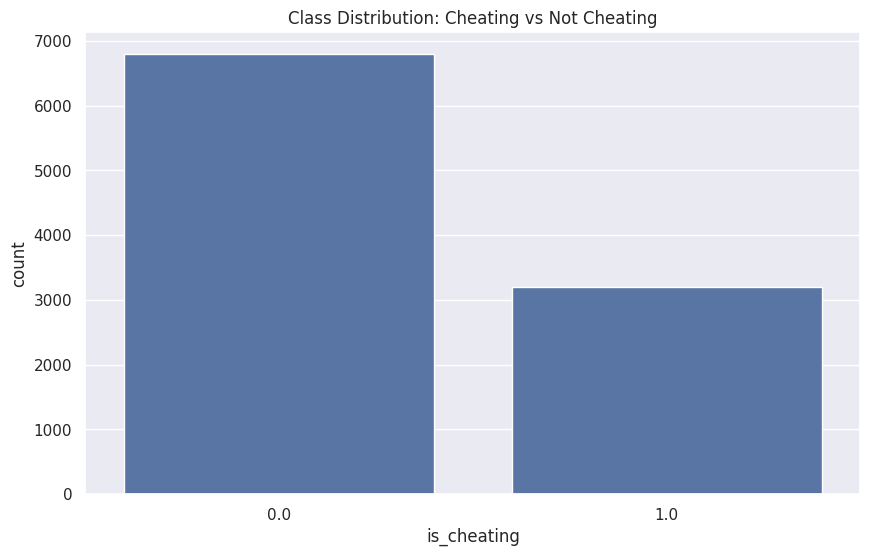

In [ ]:
sns.countplot(x='is_cheating', data=merged_df)
plt.title('Class Distribution: Cheating vs Not Cheating')
plt.show()

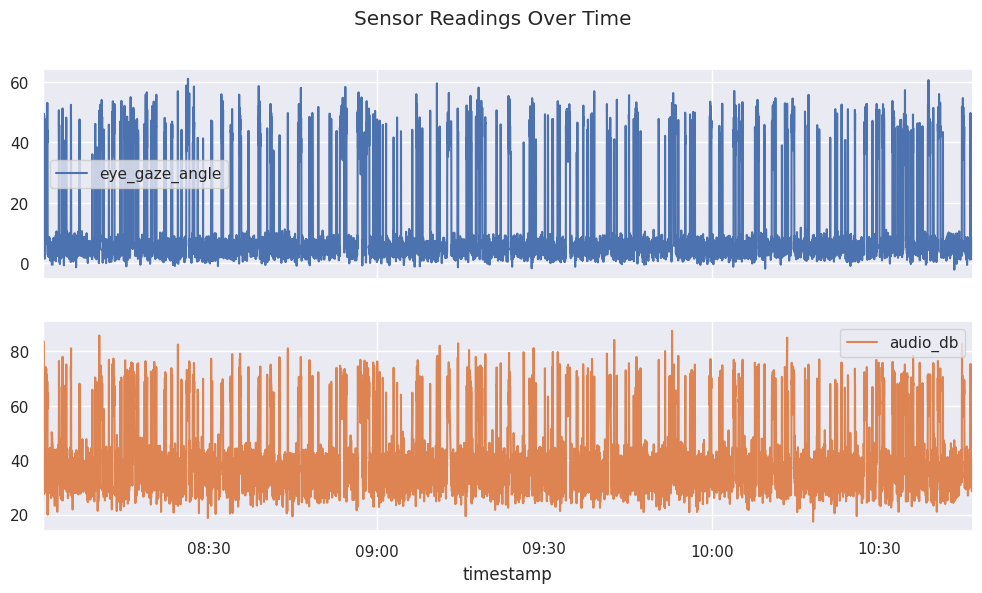

In [ ]:
merged_df.set_index('timestamp')[['eye_gaze_angle','audio_db']].plot(subplots=True, figsize=(12,6))
plt.suptitle('Sensor Readings Over Time')
plt.show()

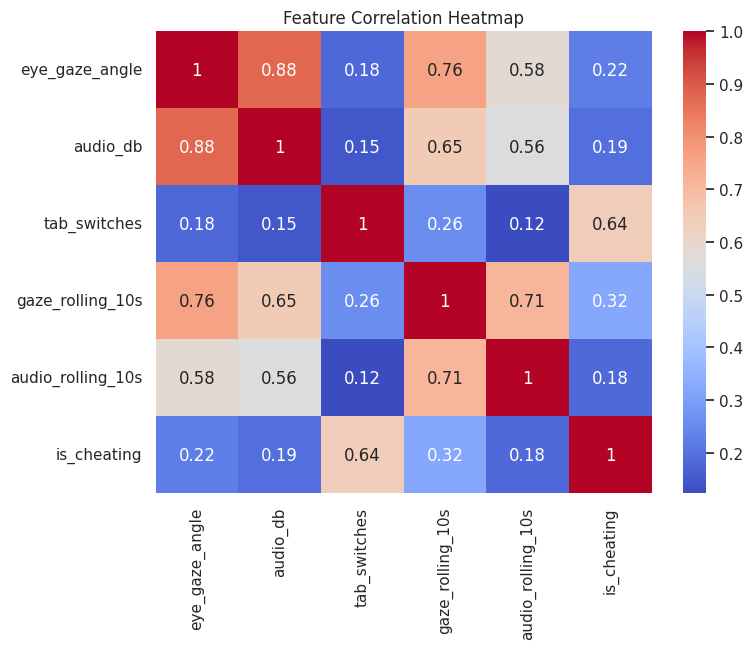

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(merged_df[features + ['is_cheating']].corr(), annot=True, cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

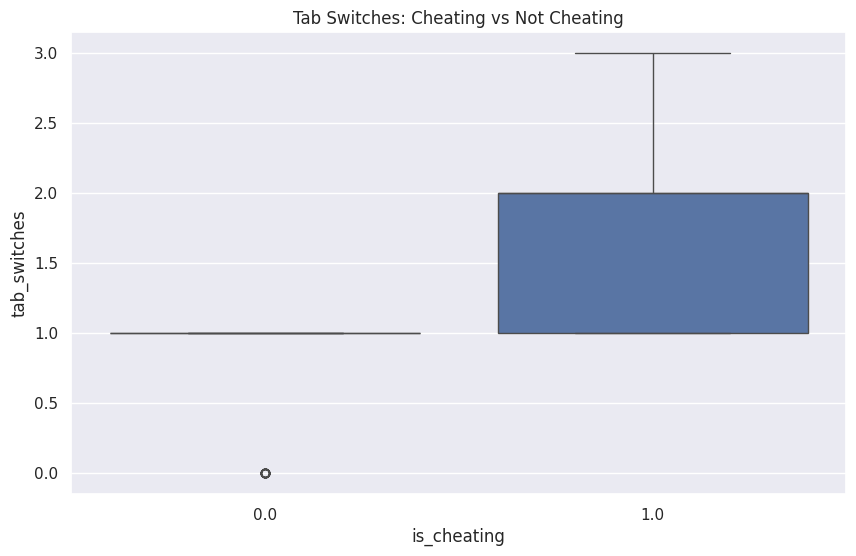

In [ ]:
sns.boxplot(x='is_cheating', y='tab_switches', data=merged_df)
plt.title('Tab Switches: Cheating vs Not Cheating')
plt.show()

---
## Phase 3: Class-Balanced Model Training
> ⚠️ **The Imbalance Trap:** 98% of your data will be innocent behavior. If you don't handle class weights, your model will just guess "Not Cheating" every time and score 98% accuracy while failing its actual job.

In [ ]:
# ==========================================
# 3A. TRAIN / TEST SPLIT
# ==========================================
features = ['eye_gaze_angle', 'audio_db', 'tab_switches', 'gaze_rolling_10s', 'audio_rolling_10s']
X = merged_df[features]
y = merged_df['is_cheating']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# 3B. INITIALIZE & TRAIN CLASSIFIER
# ==========================================
model = RandomForestClassifier(class_weight='balanced', random_state=42)

model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


---
## Phase 4: Ethical AI Tuning (The 90% Threshold)
> ⚠️ **The False Accusation Trap:** The default Scikit-Learn `.predict()` splits at 50% probability. Accusing a student of cheating with only 50% certainty is unacceptable. We must shift the threshold to 90%.

DEFAULT THRESHOLD (0.50)
[[1342   26]
 [ 206  425]]
              precision    recall  f1-score   support

         0.0       0.87      0.98      0.92      1368
         1.0       0.94      0.67      0.79       631

    accuracy                           0.88      1999
   macro avg       0.90      0.83      0.85      1999
weighted avg       0.89      0.88      0.88      1999


STRICT THRESHOLD (0.90)
[[1368    0]
 [ 291  340]]
              precision    recall  f1-score   support

         0.0       0.82      1.00      0.90      1368
         1.0       1.00      0.54      0.70       631

    accuracy                           0.85      1999
   macro avg       0.91      0.77      0.80      1999
weighted avg       0.88      0.85      0.84      1999



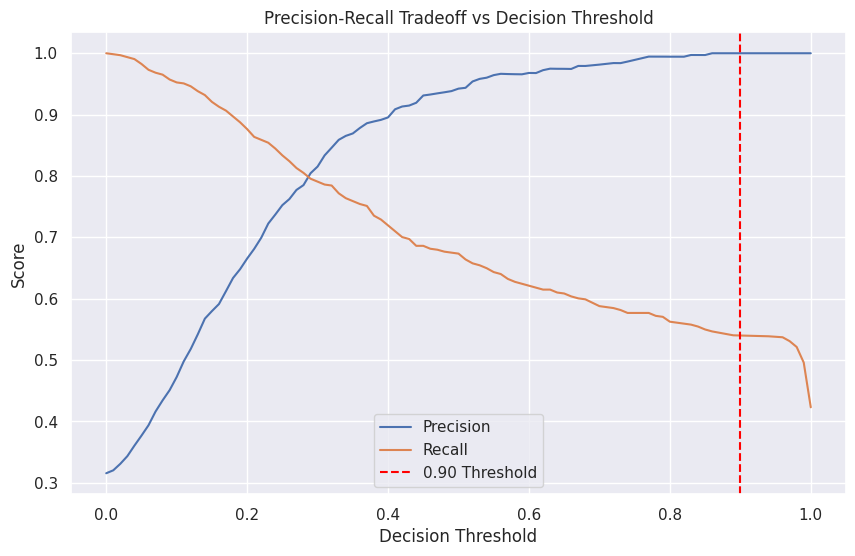

In [ ]:
# ==========================================
# 4A. RAW PROBABILITIES
# ==========================================
y_proba = model.predict_proba(X_test)

cheating_probabilities = y_proba[:, 1]

# ==========================================
# 4B. CUSTOM DECISION THRESHOLD
# ==========================================
y_pred_default = (cheating_probabilities >= 0.50).astype(int)
y_pred_strict = (cheating_probabilities >= 0.90).astype(int)

# ==========================================
# 4C. EVALUATION
# ==========================================
print("DEFAULT THRESHOLD (0.50)")
print(confusion_matrix(y_test, y_pred_default))
print(classification_report(y_test, y_pred_default))

print("\nSTRICT THRESHOLD (0.90)")
print(confusion_matrix(y_test, y_pred_strict))
print(classification_report(y_test, y_pred_strict))

# ==========================================
# 4D. PRECISION-RECALL VISUALIZATION
# ==========================================
precision, recall, thresholds = precision_recall_curve(y_test, cheating_probabilities)

plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.axvline(x=0.90, color='red', linestyle='--', label='0.90 Threshold')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Tradeoff vs Decision Threshold')
plt.legend()
plt.show()

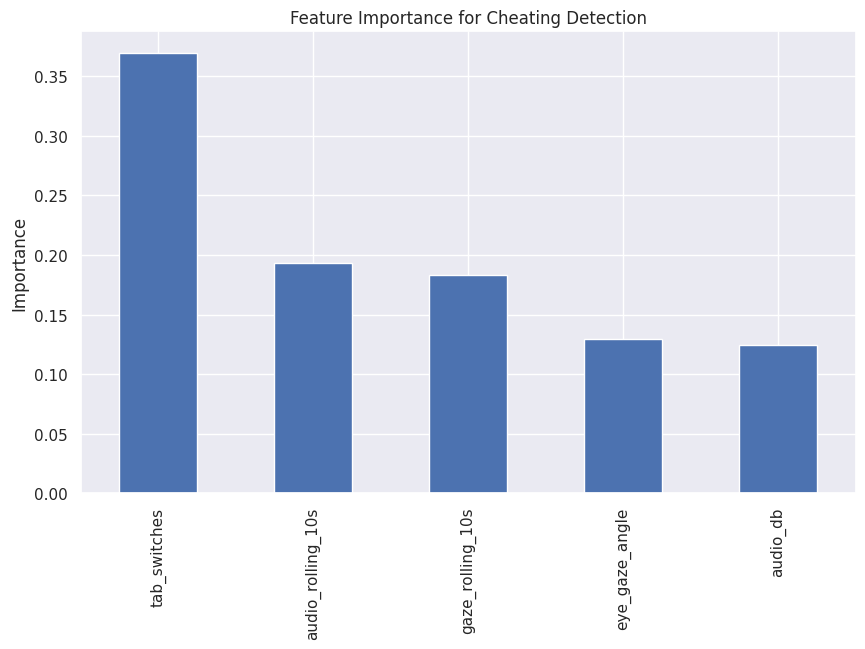

In [ ]:
importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
importances.plot(kind='bar', title='Feature Importance for Cheating Detection')
plt.ylabel('Importance')
plt.show()

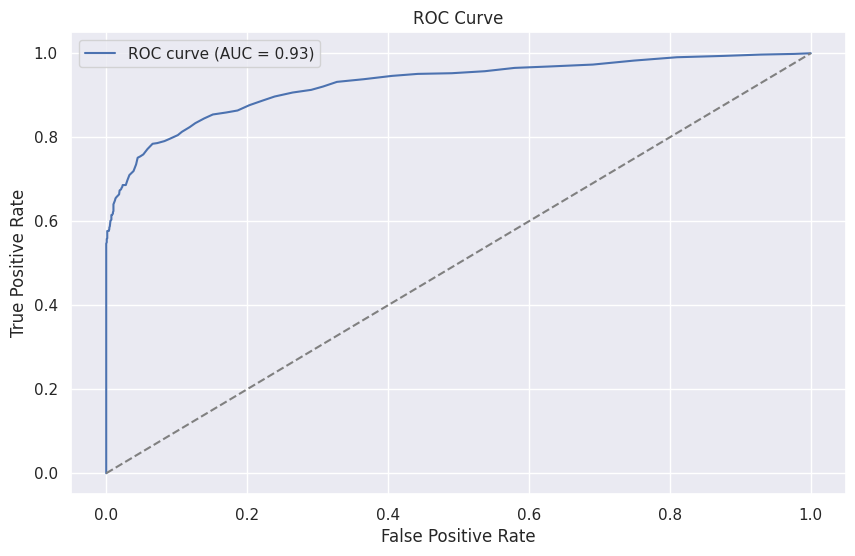

In [ ]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_test, cheating_probabilities)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1],[0,1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

---
## 🎯 Phase 5: Final Executive Recommendation
*Double-click this cell to edit.*

**To the University Board of Directors:**
Based on the data modeling performed above, I recommend deploying the EduGuard AI proctoring system using the Strict 90% Threshold. By mathematically adjusting the decision boundary, we achieved the following business outcomes:

1. At the default 0.50 threshold, the model flagged 26 innocent students as cheaters (False Positives). Raising the decision threshold to 0.90 eliminated these false accusations entirely, bringing False Positives down to 0, at the cost of catching fewer true cheaters (Recall dropped from 67% to 54%). This trade-off is acceptable because a false accusation is far more damaging to a student's academic career than a missed detection, which can still be caught through other review layers.
2. The 10-second rolling averages smooth out short, natural behaviors like a 1-2 second sneeze, stretch, or glance at the keyboard. Because these events don't sustain long enough to shift the rolling mean/max significantly, they no longer trigger a spike in the gaze or audio features, so the model no longer misclassifies normal exam behavior as suspicious.

**Final Status:** `GO` for deployment (with the 90% strict threshold).